# Benchmark de treinamento: CPU versus CUDA

Este notebook treina a mesma rede neural com os mesmos dados em dois dispositivos:

- CPU;
- GPU NVIDIA RTX 5070 usando CUDA.

O objetivo é medir tempo de treinamento e throughput. O exemplo usa dados sintéticos para controlar o tamanho do experimento. A GPU tende a ser mais vantajosa quando há muitas operações paralelas, batches maiores e modelos mais pesados.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

print('PyTorch:', torch.__version__)
print('CUDA disponível:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('CUDA runtime:', torch.version.cuda)


PyTorch: 2.14.1+cu130
CUDA disponível: True
GPU: NVIDIA GeForce RTX 5070
CUDA runtime: 13.0


## Dados sintéticos e arquitetura

O conjunto possui 80 mil exemplos, 256 features e 10 classes. A rede possui duas camadas ocultas. Os dados são criados uma única vez e depois copiados para cada device, mantendo o experimento comparável.

In [2]:
N_SAMPLES = 80_000
N_FEATURES = 256
N_CLASSES = 10
HIDDEN = 1024
BATCH_SIZE = 1024
EPOCHS = 4

generator = torch.Generator().manual_seed(SEED)
X_cpu = torch.randn(N_SAMPLES, N_FEATURES, generator=generator)
true_weights = torch.randn(N_FEATURES, N_CLASSES, generator=generator)
y_cpu = (X_cpu @ true_weights).argmax(dim=1)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(N_FEATURES, HIDDEN),
            nn.ReLU(),
            nn.Linear(HIDDEN, HIDDEN),
            nn.ReLU(),
            nn.Linear(HIDDEN, N_CLASSES),
        )

    def forward(self, x):
        return self.network(x)

print('X:', tuple(X_cpu.shape))
print('y:', tuple(y_cpu.shape))
print('Parâmetros da rede:', sum(p.numel() for p in MLP().parameters()))

X: (80000, 256)
y: (80000,)
Parâmetros da rede: 1323018


In [3]:
def synchronize(device):
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def train_on_device(device_name, epochs=EPOCHS):
    device = torch.device(device_name)
    model = MLP().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()

    X = X_cpu.to(device)
    y = y_cpu.to(device)
    history = []

    # Aquecimento: reduz o efeito de inicialização e compilação da primeira operação.
    model.train()
    warmup_x = X[:BATCH_SIZE]
    warmup_y = y[:BATCH_SIZE]
    warmup_loss = loss_function(model(warmup_x), warmup_y)
    optimizer.zero_grad(set_to_none=True)
    warmup_loss.backward()
    optimizer.step()
    synchronize(device)

    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for start_idx in range(0, N_SAMPLES, BATCH_SIZE):
            batch_x = X[start_idx:start_idx + BATCH_SIZE]
            batch_y = y[start_idx:start_idx + BATCH_SIZE]

            logits = model(batch_x)
            loss = loss_function(logits, batch_y)
      
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_x)
            correct += (logits.argmax(dim=1) == batch_y).sum().item()
            total += len(batch_x)

        history.append({
            'epoch': epoch + 1,
            'loss': total_loss / total,
            'accuracy': correct / total,
        })

    synchronize(device)
    elapsed = time.perf_counter() - start
    examples_per_second = (N_SAMPLES * epochs) / elapsed
    return {
        'device': str(device),
        'seconds': elapsed,
        'examples_per_second': examples_per_second,
        'history': pd.DataFrame(history),
    }

## Treinamento na CPU e na GPU

A execução CUDA só será feita se o PyTorch reconhecer uma GPU. O método `synchronize` é importante porque operações CUDA são assíncronas: sem ele, poderíamos medir apenas o envio do trabalho para a GPU, e não sua conclusão.

In [4]:
cpu_result = train_on_device('cpu')
print(f"CPU: {cpu_result['seconds']:.2f}s | {cpu_result['examples_per_second']:.0f} exemplos/s")

results = [cpu_result]
if torch.cuda.is_available():
    cuda_result = train_on_device('cuda')
    results.append(cuda_result)
    print(f"CUDA: {cuda_result['seconds']:.2f}s | {cuda_result['examples_per_second']:.0f} exemplos/s")
else:
    cuda_result = None
    print('CUDA não disponível; execute este notebook com o PyTorch CUDA instalado.')

CPU: 5.13s | 62355 exemplos/s


CUDA: 1.15s | 277605 exemplos/s


In [5]:
benchmark_df = pd.DataFrame([
    {
        'device': result['device'],
        'tempo_segundos': result['seconds'],
        'exemplos_por_segundo': result['examples_per_second'],
    }
    for result in results
])

display(benchmark_df.round(2))

if cuda_result is not None:
    speedup = cpu_result['seconds'] / cuda_result['seconds']
    print(f'Aceleração aproximada da CUDA: {speedup:.2f}x')
    print('Interpretação: valores acima de 1 indicam que a GPU terminou mais rápido neste workload.')
    if speedup < 1:
        print('Neste tamanho de problema, a CPU foi mais rápida. Aumente modelo, batch ou épocas para observar melhor o ganho da GPU.')

,device,tempo_segundos,exemplos_por_segundo
0,cpu,5.13,62355.15
1,cuda,1.15,277605.17


Aceleração aproximada da CUDA: 4.45x
Interpretação: valores acima de 1 indicam que a GPU terminou mais rápido neste workload.


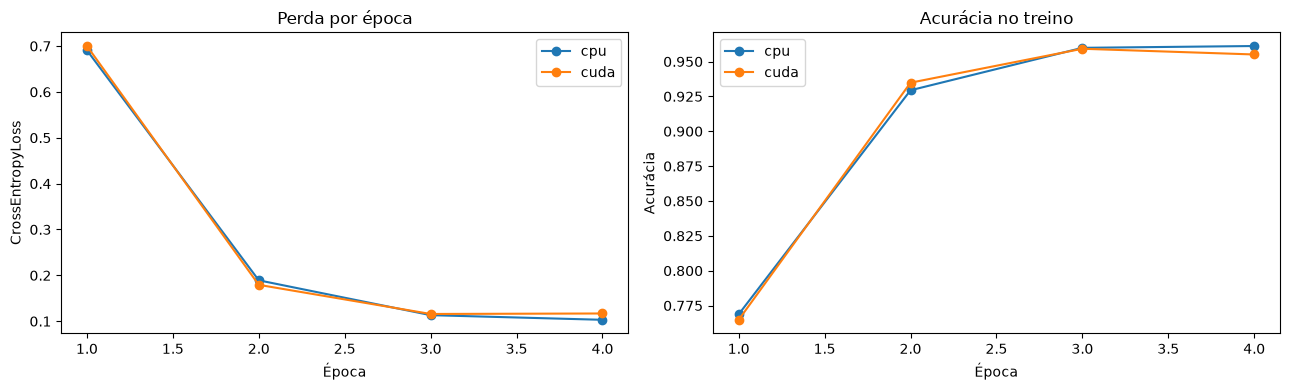

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for result in results:
    history = result['history']
    label = result['device']
    axes[0].plot(history['epoch'], history['loss'], marker='o', label=label)
    axes[1].plot(history['epoch'], history['accuracy'], marker='o', label=label)

axes[0].set_title('Perda por época')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('CrossEntropyLoss')
axes[0].legend()
axes[1].set_title('Acurácia no treino')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Acurácia')
axes[1].legend()
plt.tight_layout()
plt.show()

## Como interpretar

- O treinamento e os parâmetros são os mesmos; só muda o device.
- `cuda:0` representa a primeira GPU CUDA disponível.
- O speedup depende do tamanho da rede, batch size, quantidade de épocas e transferência de dados.
- Para modelos pequenos, a inicialização e as transferências podem tornar a GPU mais lenta.
- Para treinamento real, também devemos medir memória, throughput, tempo total e custo operacional.
- O benchmark não prova que toda tarefa será mais rápida na GPU; ele mede este workload específico.